In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="6aa8AyuTmZDUFZnUlbd7")
project = rf.workspace("sarah-cho").project("product-detection-n9ifd-jott9")
version = project.version(1)
dataset = version.download("yolov8")
                

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.6/324.6 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 93.3 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Product-Detection-1 in yolov8:: 100%|██████████| 1728/1728 [00:00<00:00, 8428.89it/s]


In [2]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 6.9 MB/s eta 0:00:00


In [3]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')  # nano — fastest, good for proof-of-concept
results = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=25,
    imgsz=416,
    batch=16
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.161 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Product-Detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/25      1.13G      1.392      1.323      1.365         29        416: 100% ━━━━━━━━━━━━ 38/38 13.7it/s 2.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 8.6it/s 0.7s
                   all        165        349      0.591      0.639      0.621      0.316

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/25      1.13G      1.416      1.297      1.368         59        416: 100% ━━━━━━━━━━━━ 38/38 13.6it/s 2.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 9.6it/s 0.6s
                   all        165        349      0.468      0.573      0.512      0.257

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/25      1.14G      1.407      1.264      1.399         35        416: 100% ━━━━━━━━━━━━ 38/38 14.4it/s 2.6s
                 Class     Images  Instances      Box(P        

In [4]:
metrics = model.val()
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")

Ultralytics 8.4.161 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1391.3±490.6 MB/s, size: 48.4 KB)
val: Scanning /kaggle/working/Product-Detection-1/valid/labels.cache... 168 images, 6 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 168/168 64.1Mit/s 0.0s
val: /kaggle/working/Product-Detection-1/valid/images/123-61-_jpg.rf.d9cf18a3bddfaaf6687238807d6558a2.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/Product-Detection-1/valid/images/271533843_672243013782336_1922457198840694656_n_jpg.rf.7c007637faac5f6993b0268b4a26227d.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/Product-Detection-1/valid/images/IMG_9710_JPG_jpg.rf.ccba7f1377b283c9fbe572d70a99d896.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment coun

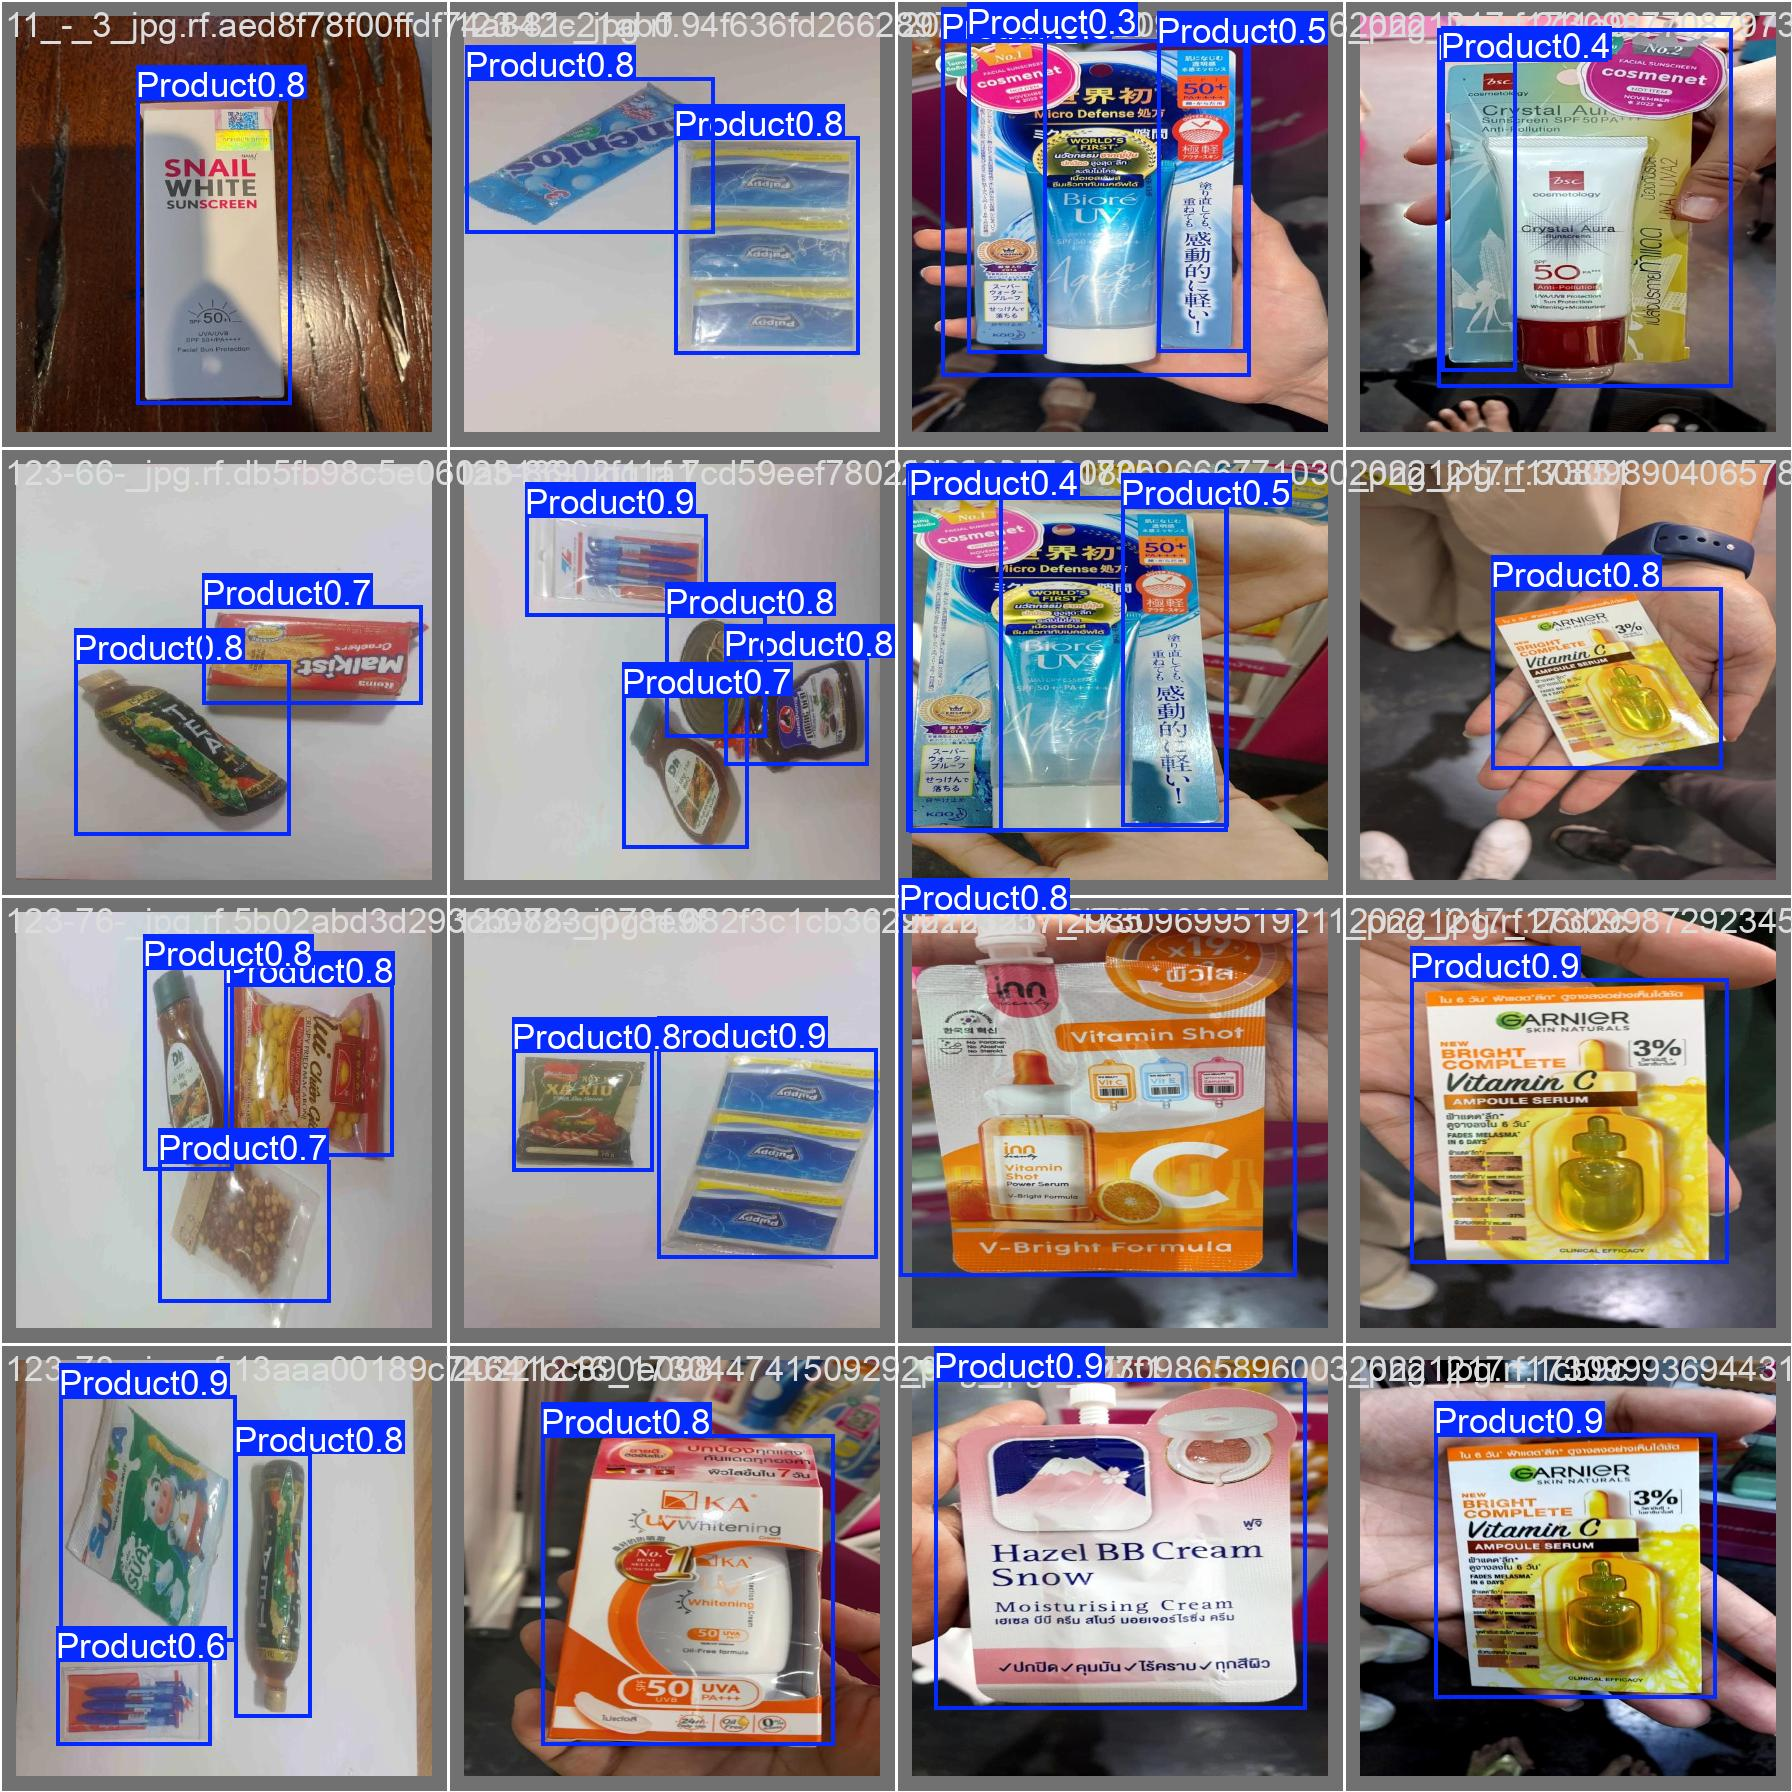

In [5]:
import glob
from IPython.display import Image, display

# find a val batch prediction image with boxes drawn
for img_path in glob.glob('/kaggle/working/runs/detect/train/val_batch0_pred.jpg'):
    display(Image(filename=img_path))